## Step 1 — Install & Import Libraries

In [1]:
!pip install scikit-learn pandas numpy matplotlib seaborn xgboost tensorflow -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import pickle
import ast
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.pipeline import Pipeline

# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier,
                               GradientBoostingClassifier)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

# ANN
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    roc_curve, roc_auc_score
)

print('✅ All libraries imported successfully!')

✅ All libraries imported successfully!


## Step 2 — Load Dataset

**Source:** [TMDB 5000 Movie Dataset — Kaggle](https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata)

In [3]:
# Load dataset
# Download from: https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata
movies = pd.read_csv('movies.csv')

print('Dataset Shape    :', movies.shape)
print('Columns          :', list(movies.columns))
display(movies.head(3))

Dataset Shape    : (4803, 20)
Columns          : ['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count']


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466


In [4]:
print('=== First 5 rows ===')
display(movies.head(5))
print()
print('=== Data Types ===')
print(movies.dtypes)

=== First 5 rows ===


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124



=== Data Types ===
budget                    int64
genres                   object
homepage                 object
id                        int64
keywords                 object
original_language        object
original_title           object
overview                 object
popularity              float64
production_companies     object
production_countries     object
release_date             object
revenue                   int64
runtime                 float64
spoken_languages         object
status                   object
tagline                  object
title                    object
vote_average            float64
vote_count                int64
dtype: object


## Step 3 — Data Preprocessing

In [5]:
# 3.1 Check Missing Values
print('=== Missing Values ===')
print(movies.isnull().sum())

=== Missing Values ===
budget                     0
genres                     0
homepage                3091
id                         0
keywords                   0
original_language          0
original_title             0
overview                   3
popularity                 0
production_companies       0
production_countries       0
release_date               1
revenue                    0
runtime                    2
spoken_languages           0
status                     0
tagline                  844
title                      0
vote_average               0
vote_count                 0
dtype: int64


In [6]:
# 3.2 Check Duplicates
print(f'Duplicate rows: {movies.duplicated().sum()}')

Duplicate rows: 0


In [7]:
# 3.3 Clean & Prepare Data
cols = ['budget','revenue','vote_average','vote_count',
        'popularity','runtime','title','genres','overview','release_date']
df = movies[[c for c in cols if c in movies.columns]].copy()

# Remove zero / invalid values
df = df[(df['budget'] > 0) & (df['vote_count'] > 0) & (df['vote_average'] > 0)]
df = df.dropna()

# Budget & Revenue in millions
df['budget_m']  = df['budget']  / 1_000_000
df['revenue_m'] = df['revenue'] / 1_000_000

# Extract release year
if 'release_date' in df.columns:
    df['release_year'] = pd.to_datetime(df['release_date'], errors='coerce').dt.year
    df = df.dropna(subset=['release_year'])
    df['release_year'] = df['release_year'].astype(int)

# Target Variable: Blockbuster = Revenue > Budget × 2
df['is_good'] = (df['revenue'] > df['budget'] * 2).astype(int)

print(f'Clean Dataset Shape : {df.shape}')
print(f'Blockbuster Movies  : {df["is_good"].sum()} ({df["is_good"].mean()*100:.1f}%)')
print(f'Non-Blockbuster     : {(df["is_good"]==0).sum()} ({(df["is_good"]==0).mean()*100:.1f}%)')
display(df[['title','budget_m','revenue_m','vote_average','vote_count','is_good']].head())

Clean Dataset Shape : (3753, 14)
Blockbuster Movies  : 1804 (48.1%)
Non-Blockbuster     : 1949 (51.9%)


,title,budget_m,revenue_m,vote_average,vote_count,is_good
0,Avatar,237.0,2787.965087,7.2,11800,1
1,Pirates of the Caribbean: At World's End,300.0,961.000000,6.9,4500,1
2,Spectre,245.0,880.674609,6.3,4466,1
3,The Dark Knight Rises,250.0,1084.939099,7.6,9106,1
4,John Carter,260.0,284.139100,6.1,2124,0


In [8]:
# 3.4 Statistical Description
print('=== Statistical Description ===')
display(df[['budget_m','revenue_m','vote_average','vote_count','popularity']].describe())

=== Statistical Description ===


,budget_m,revenue_m,vote_average,vote_count,popularity
count,3753.000000,3753.000000,3753.000000,3753.000000,3753.000000
mean,37.164737,104.314814,6.244125,859.458300,26.073578
std,42.669282,177.841782,0.906743,1346.169772,34.464616
min,0.000001,0.000000,2.000000,1.000000,0.001586
25%,8.000000,6.420319,5.700000,116.000000,8.083995
50%,23.000000,39.143839,6.300000,368.000000,17.659032
75%,50.000000,122.233971,6.900000,973.000000,34.005726
max,380.000000,2787.965087,10.000000,13752.000000,875.581305


In [9]:
# 3.5 Encode + Scale
features = ['budget_m','popularity','vote_count','revenue_m']
if 'runtime' in df.columns:
    features.append('runtime')
if 'release_year' in df.columns:
    features.append('release_year')

X = df[features].values
y = df['is_good'].values

# Train-Test Split (80-20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standard Scaling
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc  = sc.transform(X_test)

print(f'Training Samples : {len(X_train)} (80%)')
print(f'Testing  Samples : {len(X_test)}  (20%)')
print(f'Features Used    : {features}')

Training Samples : 3002 (80%)
Testing  Samples : 751  (20%)
Features Used    : ['budget_m', 'popularity', 'vote_count', 'revenue_m', 'runtime', 'release_year']


Training complete! Graph ban raha hai...


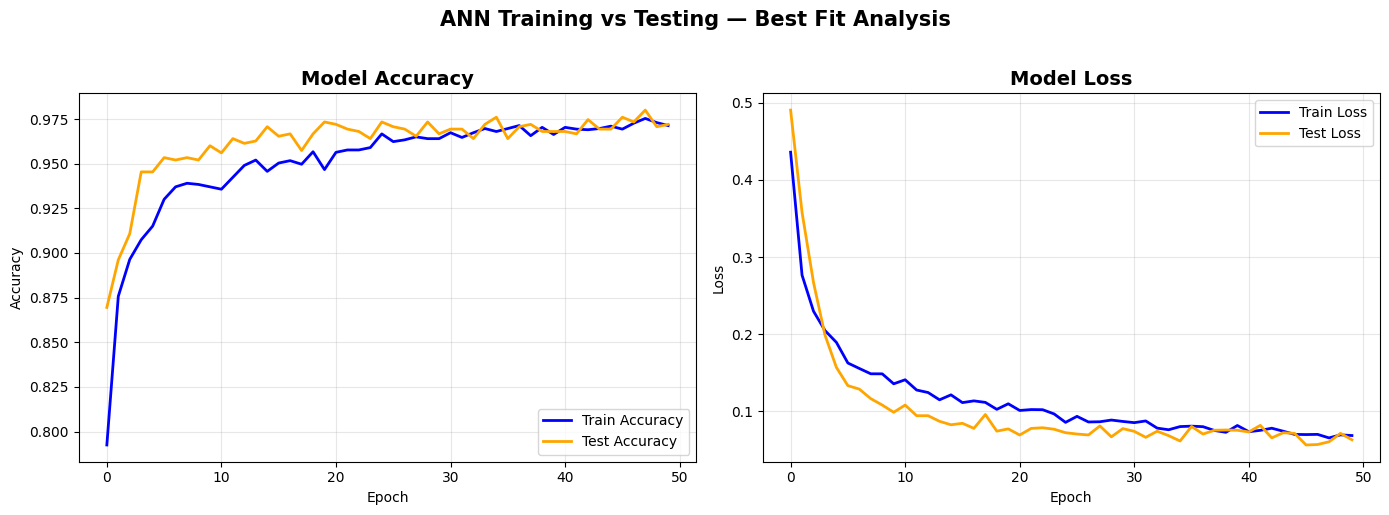

Saved: ann_best_fit.png

  Final Train Accuracy : 97.14%
  Final Test  Accuracy : 97.20%
  Gap                  : 0.07%
  ✅ MODEL IS BEST FIT — Train ≈ Test Accuracy


In [10]:
# ============================================================
# ANN Training History — Best Fit Graph
# ============================================================

# Train karo history ke saath
tf.random.set_seed(42)
ann_history_model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_sc.shape[1],)),
    BatchNormalization(), Dropout(0.3),
    Dense(64, activation='relu'),
    BatchNormalization(), Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])
ann_history_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = ann_history_model.fit(
    X_train_sc, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test_sc, y_test),  # Test data bhi pass karo
    verbose=0
)

print("Training complete! Graph ban raha hai...")

# ---- Graphs ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Graph (a) — Accuracy
ax1.plot(history.history['accuracy'],     color='blue',   linewidth=2, label='Train Accuracy')
ax1.plot(history.history['val_accuracy'], color='orange', linewidth=2, label='Test Accuracy')
ax1.set_title('Model Accuracy', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Graph (b) — Loss
ax2.plot(history.history['loss'],     color='blue',   linewidth=2, label='Train Loss')
ax2.plot(history.history['val_loss'], color='orange', linewidth=2, label='Test Loss')
ax2.set_title('Model Loss', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle('ANN Training vs Testing — Best Fit Analysis',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('ann_best_fit.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: ann_best_fit.png')

# ---- Best Fit Check ----
final_train_acc = history.history['accuracy'][-1]
final_test_acc  = history.history['val_accuracy'][-1]
gap = abs(final_train_acc - final_test_acc)

print(f"\n{'='*45}")
print(f"  Final Train Accuracy : {final_train_acc*100:.2f}%")
print(f"  Final Test  Accuracy : {final_test_acc*100:.2f}%")
print(f"  Gap                  : {gap*100:.2f}%")
print(f"{'='*45}")
if gap < 0.05:
    print("  ✅ MODEL IS BEST FIT — Train ≈ Test Accuracy")
elif gap < 0.10:
    print("  ⚠️  SLIGHT OVERFIT — Acceptable Range")
else:
    print("  ❌ OVERFITTING DETECTED")
print(f"{'='*45}")

Training complete! Graph ban raha hai...


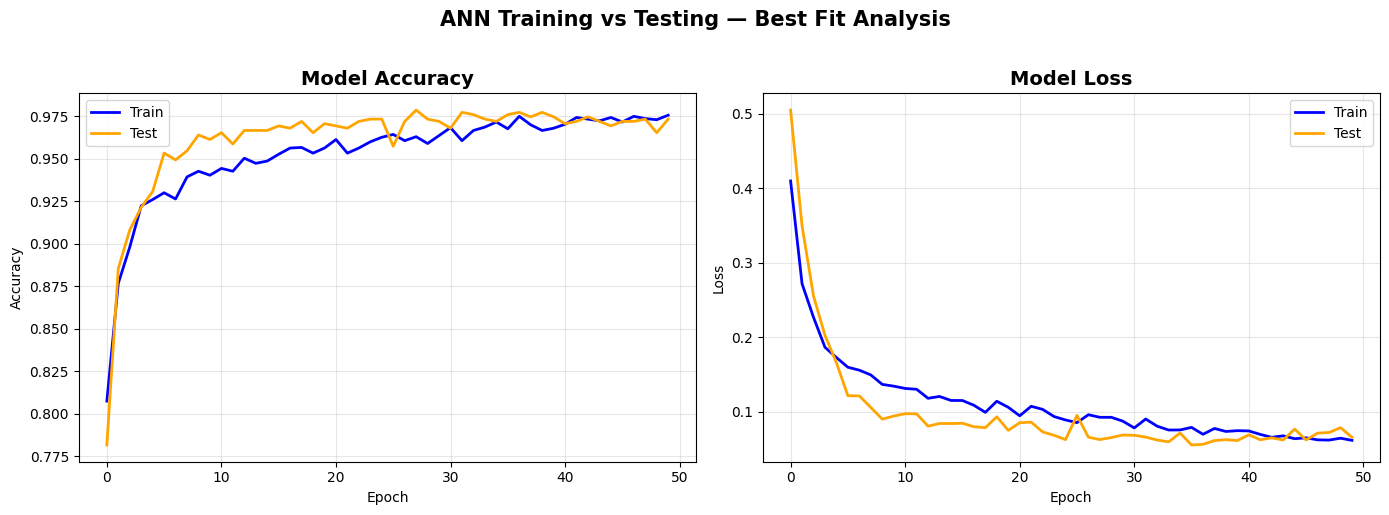


  Final Train Accuracy : 97.57%
  Final Test  Accuracy : 97.34%
  Gap                  : 0.23%
  ✅ MODEL IS BEST FIT — Train ≈ Test Accuracy



In [11]:
# ============================================================
# ANN Training History — Best Fit Graph
# ============================================================

tf.random.set_seed(42)
ann_hist_model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_sc.shape[1],)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])
ann_hist_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = ann_hist_model.fit(
    X_train_sc, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test_sc, y_test),
    verbose=0
)

print("Training complete! Graph ban raha hai...")

# ---- Graphs ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['accuracy'],     color='blue',   linewidth=2, label='Train')
ax1.plot(history.history['val_accuracy'], color='orange', linewidth=2, label='Test')
ax1.set_title('Model Accuracy', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history.history['loss'],     color='blue',   linewidth=2, label='Train')
ax2.plot(history.history['val_loss'], color='orange', linewidth=2, label='Test')
ax2.set_title('Model Loss', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle('ANN Training vs Testing — Best Fit Analysis',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('ann_best_fit.png', dpi=150, bbox_inches='tight')
plt.show()

# ---- Best Fit Check ----
final_train_acc = history.history['accuracy'][-1]
final_test_acc  = history.history['val_accuracy'][-1]
gap = abs(final_train_acc - final_test_acc)

print(f"\n{'='*45}")
print(f"  Final Train Accuracy : {final_train_acc*100:.2f}%")
print(f"  Final Test  Accuracy : {final_test_acc*100:.2f}%")
print(f"  Gap                  : {gap*100:.2f}%")
print(f"{'='*45}")
if gap < 0.05:
    print("  ✅ MODEL IS BEST FIT — Train ≈ Test Accuracy")
elif gap < 0.10:
    print("  ⚠️  SLIGHT OVERFIT — Acceptable Range")
else:
    print("  ❌ OVERFITTING DETECTED")
print(f"{'='*45}\n")

## Step 4 — Feature Extraction (TF-IDF + PCA)

In [12]:
# TF-IDF on movie overview (for content-based recommendation)
if 'overview' in df.columns:
    df['overview'] = df['overview'].fillna('')
    tfidf = TfidfVectorizer(max_features=100, stop_words='english')
    tfidf_matrix = tfidf.fit_transform(df['overview'])
    print(f'TF-IDF Matrix Shape: {tfidf_matrix.shape}')
    print('Top 10 TF-IDF features:')
    print(tfidf.get_feature_names_out()[:10])
else:
    print('overview column not found — skipping TF-IDF')

TF-IDF Matrix Shape: (3753, 100)
Top 10 TF-IDF features:
['agent' 'american' 'based' 'battle' 'begins' 'best' 'big' 'boy' 'brother'
 'city']


PCA Explained Variance Ratio:
  Component 1: 52.55%
  Component 2: 19.56%
  Component 3: 11.78%
  Component 4: 9.41%
  Component 5: 4.21%
  Component 6: 2.49%
  Total Explained: 100.00%


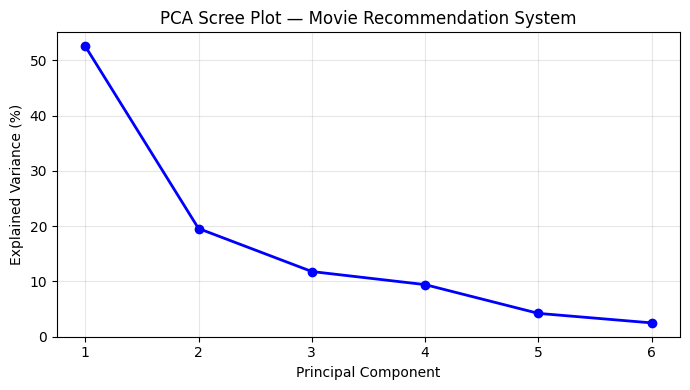

Saved: pca_scree.png


In [13]:
# PCA Feature Extraction
pca = PCA(n_components=min(6, len(features)))
X_pca = pca.fit_transform(X_train_sc)

print('PCA Explained Variance Ratio:')
for i, v in enumerate(pca.explained_variance_ratio_):
    print(f'  Component {i+1}: {v*100:.2f}%')
print(f'  Total Explained: {pca.explained_variance_ratio_.sum()*100:.2f}%')

# PCA Scree Plot
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(pca.explained_variance_ratio_)+1),
         pca.explained_variance_ratio_*100, 'bo-', linewidth=2)
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance (%)')
plt.title('PCA Scree Plot — Movie Recommendation System')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('pca_scree.png', dpi=150)
plt.show()
print('Saved: pca_scree.png')

## Step 5 — Train 10 Classification Models
### Goal: Classify if a movie is a Blockbuster (Revenue > Budget × 2)

In [14]:
# MODEL 1: Logistic Regression
lr = LogisticRegression(max_iter=1000, C=10, random_state=42)
lr.fit(X_train_sc, y_train)
y_pred_lr = lr.predict(X_test_sc)
acc_lr = accuracy_score(y_test, y_pred_lr)
print(f'1. Logistic Regression   : {acc_lr*100:.2f}%')

1. Logistic Regression   : 96.80%


In [15]:
# MODEL 2: Decision Tree
dt = DecisionTreeClassifier(max_depth=8, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
acc_dt = accuracy_score(y_test, y_pred_dt)
print(f'2. Decision Tree         : {acc_dt*100:.2f}%')

2. Decision Tree         : 97.74%


In [16]:
# MODEL 3: Random Forest
rf = RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)
print(f'3. Random Forest         : {acc_rf*100:.2f}%')

3. Random Forest         : 97.20%


In [17]:
# MODEL 4: SVM
svm = SVC(probability=True, C=10, random_state=42)
svm.fit(X_train_sc, y_train)
y_pred_svm = svm.predict(X_test_sc)
acc_svm = accuracy_score(y_test, y_pred_svm)
print(f'4. SVM                   : {acc_svm*100:.2f}%')

4. SVM                   : 95.87%


In [18]:
# MODEL 5: KNN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_sc, y_train)
y_pred_knn = knn.predict(X_test_sc)
acc_knn = accuracy_score(y_test, y_pred_knn)
print(f'5. KNN                   : {acc_knn*100:.2f}%')

5. KNN                   : 86.55%


In [19]:
# MODEL 6: Naive Bayes
nb = GaussianNB()
nb.fit(X_train_sc, y_train)
y_pred_nb = nb.predict(X_test_sc)
acc_nb = accuracy_score(y_test, y_pred_nb)
print(f'6. Naive Bayes           : {acc_nb*100:.2f}%')

6. Naive Bayes           : 70.44%


In [20]:
# MODEL 7: AdaBoost
ada = AdaBoostClassifier(n_estimators=200, random_state=42)
ada.fit(X_train, y_train)
y_pred_ada = ada.predict(X_test)
acc_ada = accuracy_score(y_test, y_pred_ada)
print(f'7. AdaBoost              : {acc_ada*100:.2f}%')

7. AdaBoost              : 97.74%


In [21]:
# MODEL 8: Gradient Boosting
gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, random_state=42)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)
acc_gb = accuracy_score(y_test, y_pred_gb)
print(f'8. Gradient Boosting     : {acc_gb*100:.2f}%')

8. Gradient Boosting     : 98.14%


In [22]:
# MODEL 9: XGBoost
xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                    random_state=42, eval_metric='logloss', n_jobs=-1)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)
acc_xgb = accuracy_score(y_test, y_pred_xgb)
print(f'9. XGBoost               : {acc_xgb*100:.2f}%')

9. XGBoost               : 98.54%


In [23]:
# MODEL 10: ANN (Artificial Neural Network)
tf.random.set_seed(42)
ann = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_sc.shape[1],)),
    BatchNormalization(), Dropout(0.3),
    Dense(64, activation='relu'),
    BatchNormalization(), Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])
ann.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
es = EarlyStopping(patience=5, restore_best_weights=True)
ann.fit(X_train_sc, y_train, epochs=50, batch_size=32,
        validation_split=0.1, callbacks=[es], verbose=0)
y_pred_ann = (ann.predict(X_test_sc, verbose=0) > 0.5).astype(int).flatten()
acc_ann = accuracy_score(y_test, y_pred_ann)
print(f'10. ANN                  : {acc_ann*100:.2f}%')

10. ANN                  : 97.60%


## Step 6 — Model Evaluation

In [24]:
# Collect all model results
model_results = {
    'Logistic Regression': {'acc': acc_lr,  'pred': y_pred_lr,  'scaled': True,  'obj': lr},
    'Decision Tree'      : {'acc': acc_dt,  'pred': y_pred_dt,  'scaled': False, 'obj': dt},
    'Random Forest'      : {'acc': acc_rf,  'pred': y_pred_rf,  'scaled': False, 'obj': rf},
    'SVM'                : {'acc': acc_svm, 'pred': y_pred_svm, 'scaled': True,  'obj': svm},
    'KNN'                : {'acc': acc_knn, 'pred': y_pred_knn, 'scaled': True,  'obj': knn},
    'Naive Bayes'        : {'acc': acc_nb,  'pred': y_pred_nb,  'scaled': True,  'obj': nb},
    'AdaBoost'           : {'acc': acc_ada, 'pred': y_pred_ada, 'scaled': False, 'obj': ada},
    'Gradient Boosting'  : {'acc': acc_gb,  'pred': y_pred_gb,  'scaled': False, 'obj': gb},
    'XGBoost'            : {'acc': acc_xgb, 'pred': y_pred_xgb, 'scaled': False, 'obj': xgb},
    'ANN'                : {'acc': acc_ann, 'pred': y_pred_ann, 'scaled': True,  'obj': None},
}

# ROC-AUC probability map
roc_proba_map = {
    'Logistic Regression': (lr,  X_test_sc),
    'Decision Tree'      : (dt,  X_test),
    'Random Forest'      : (rf,  X_test),
    'SVM'                : (svm, X_test_sc),
    'KNN'                : (knn, X_test_sc),
    'Naive Bayes'        : (nb,  X_test_sc),
    'AdaBoost'           : (ada, X_test),
    'Gradient Boosting'  : (gb,  X_test),
    'XGBoost'            : (xgb, X_test),
}

# Full Evaluation Table with ROC-AUC
print('='*95)
print(f"{'Model':<22} {'Accuracy':>9} {'Precision':>10} {'Recall':>8} {'F1':>8} {'ROC-AUC':>9}")
print('='*95)
eval_data = []
for name, info in sorted(model_results.items(), key=lambda x: -x[1]['acc']):
    yp   = info['pred']
    acc  = accuracy_score(y_test, yp)
    prec = precision_score(y_test, yp, zero_division=0)
    rec  = recall_score(y_test, yp, zero_division=0)
    f1   = f1_score(y_test, yp, zero_division=0)

    if name == 'ANN':
        prob = ann.predict(X_test_sc, verbose=0).flatten()
    else:
        model_obj, Xte = roc_proba_map[name]
        prob = model_obj.predict_proba(Xte)[:, 1]
    auc = roc_auc_score(y_test, prob)

    print(f"{name:<22} {acc*100:>8.2f}% {prec*100:>9.2f}% {rec*100:>7.2f}% {f1*100:>7.2f}% {auc:>9.4f}")
    eval_data.append({
        'Model'    : name,
        'Accuracy' : round(acc*100, 2),
        'Precision': round(prec*100, 2),
        'Recall'   : round(rec*100, 2),
        'F1'       : round(f1*100, 2),
        'ROC-AUC'  : round(auc, 4)
    })
print('='*95)

best_name = max(model_results, key=lambda x: model_results[x]['acc'])
best_acc  = model_results[best_name]['acc']
print(f'\n🏆 Best Model: {best_name} ({best_acc*100:.2f}%)')

Model                   Accuracy  Precision   Recall       F1   ROC-AUC
XGBoost                   98.54%     98.88%   98.06%   98.47%    0.9980
Gradient Boosting         98.14%     98.33%   97.78%   98.06%    0.9967
Decision Tree             97.74%     97.78%   97.51%   97.64%    0.9793
AdaBoost                  97.74%     98.04%   97.23%   97.64%    0.9955
ANN                       97.60%     97.25%   97.78%   97.51%    0.9986
Random Forest             97.20%     97.22%   96.95%   97.09%    0.9949
Logistic Regression       96.80%     98.01%   95.29%   96.63%    0.9973
SVM                       95.87%     96.88%   94.46%   95.65%    0.9940
KNN                       86.55%     87.57%   83.93%   85.71%    0.9317
Naive Bayes               70.44%     84.92%   46.81%   60.36%    0.8061

🏆 Best Model: XGBoost (98.54%)


In [25]:
# Classification Report — Best Model
best_pred = model_results[best_name]['pred']
print(f'{"="*60}')
print(f'  CLASSIFICATION REPORT — {best_name}')
print(f'{"="*60}')
print(classification_report(y_test, best_pred,
      target_names=['Not Blockbuster', 'Blockbuster']))

  CLASSIFICATION REPORT — XGBoost
                 precision    recall  f1-score   support

Not Blockbuster       0.98      0.99      0.99       390
    Blockbuster       0.99      0.98      0.98       361

       accuracy                           0.99       751
      macro avg       0.99      0.99      0.99       751
   weighted avg       0.99      0.99      0.99       751



## Step 7 — Graphical Analysis

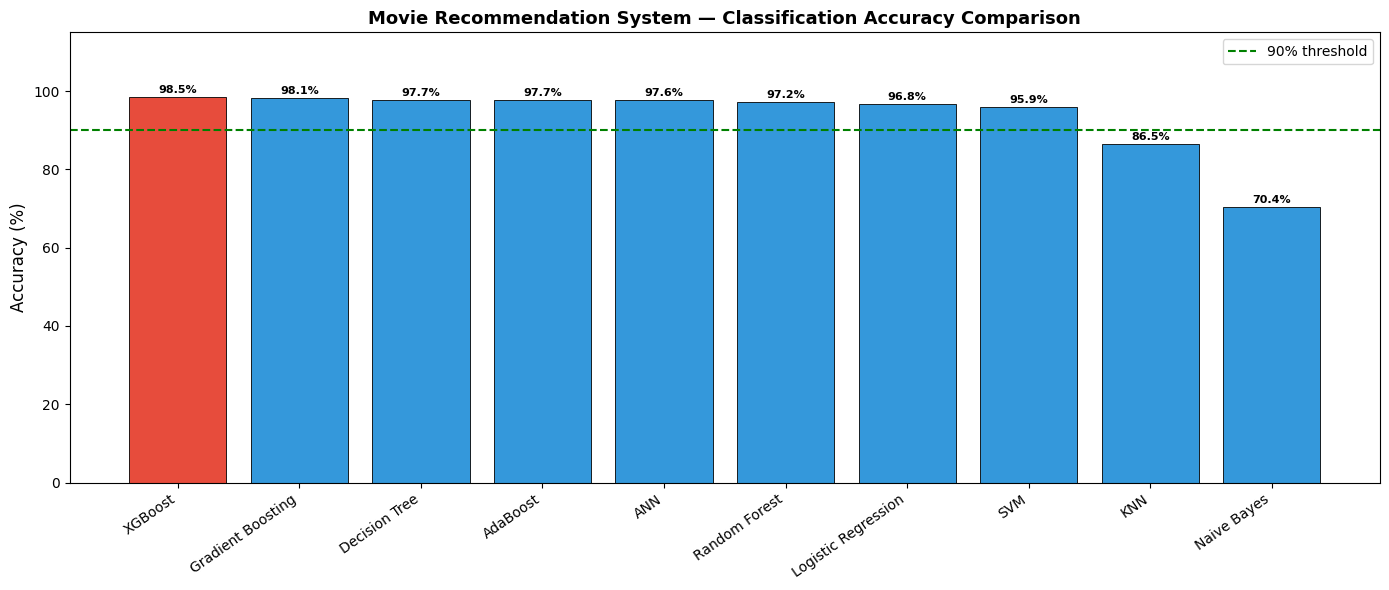

Saved: accuracy_comparison.png


In [26]:
# GRAPH 1: Accuracy Comparison Bar Chart
names  = [d['Model'] for d in eval_data]
scores = [d['Accuracy'] for d in eval_data]
colors = ['#e74c3c' if n == best_name else '#3498db' for n in names]

plt.figure(figsize=(14, 6))
bars = plt.bar(names, scores, color=colors, edgecolor='black', linewidth=0.6)
plt.xticks(rotation=35, ha='right', fontsize=10)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.ylim(0, 115)
plt.title('Movie Recommendation System — Classification Accuracy Comparison',
          fontsize=13, fontweight='bold')
for bar, score in zip(bars, scores):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
             f'{score:.1f}%', ha='center', va='bottom', fontsize=8, fontweight='bold')
plt.axhline(y=90, color='green', linestyle='--', linewidth=1.5, label='90% threshold')
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig('accuracy_comparison.png', dpi=150)
plt.show()
print('Saved: accuracy_comparison.png')

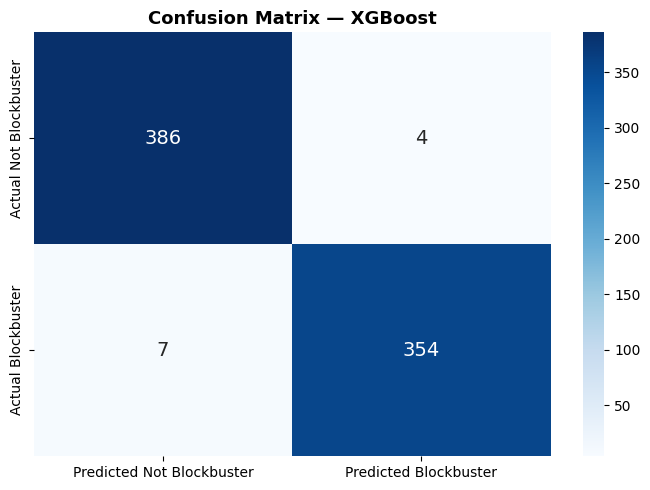

Saved: confusion_matrix.png


In [27]:
# GRAPH 2: Confusion Matrix — Best Model
cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Not Blockbuster', 'Predicted Blockbuster'],
            yticklabels=['Actual Not Blockbuster', 'Actual Blockbuster'],
            annot_kws={'size': 14})
plt.title(f'Confusion Matrix — {best_name}', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()
print('Saved: confusion_matrix.png')

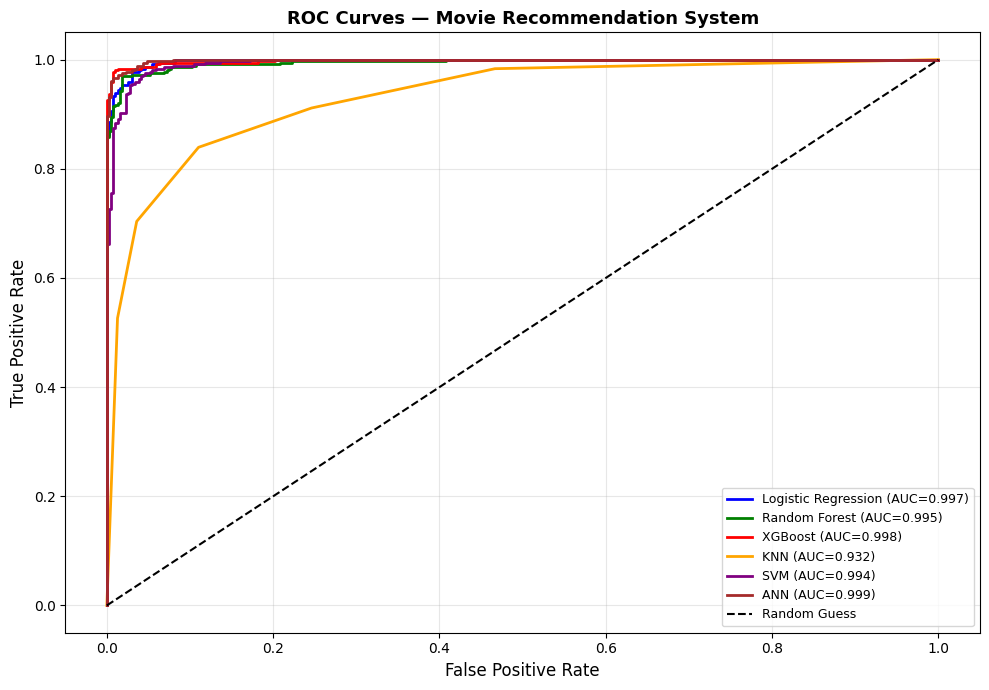

Saved: roc_curves.png


In [28]:
# GRAPH 3: ROC Curves — Multiple Models
plt.figure(figsize=(10, 7))
roc_models = {
    'Logistic Regression': (lr,  X_test_sc),
    'Random Forest'      : (rf,  X_test),
    'XGBoost'            : (xgb, X_test),
    'KNN'                : (knn, X_test_sc),
    'SVM'                : (svm, X_test_sc),
}
colors_roc = ['blue', 'green', 'red', 'orange', 'purple']
for (name, (model, Xte)), col in zip(roc_models.items(), colors_roc):
    prob = model.predict_proba(Xte)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, color=col, linewidth=2, label=f'{name} (AUC={auc:.3f})')

prob_ann = ann.predict(X_test_sc, verbose=0).flatten()
fpr_ann, tpr_ann, _ = roc_curve(y_test, prob_ann)
auc_ann = roc_auc_score(y_test, prob_ann)
plt.plot(fpr_ann, tpr_ann, color='brown', linewidth=2, label=f'ANN (AUC={auc_ann:.3f})')
plt.plot([0,1], [0,1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves — Movie Recommendation System', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=150)
plt.show()
print('Saved: roc_curves.png')

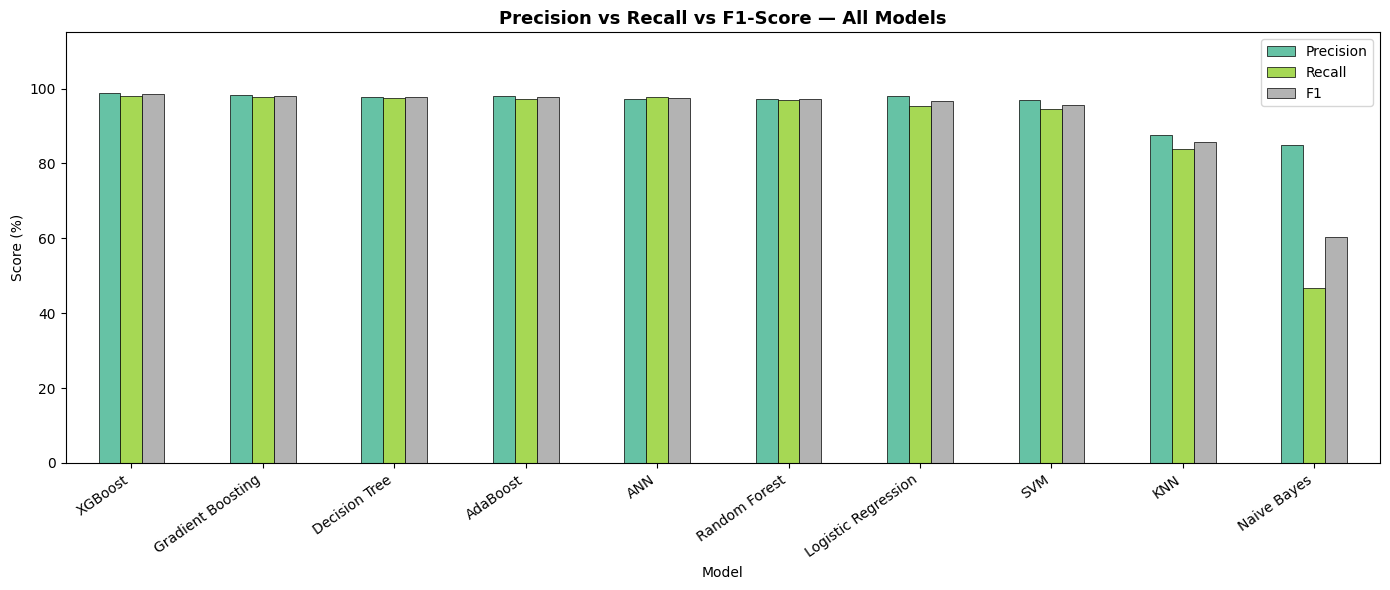

Saved: precision_recall_f1.png


In [29]:
# GRAPH 4: Precision, Recall, F1 Comparison
df_eval = pd.DataFrame(eval_data).set_index('Model')
df_eval[['Precision', 'Recall', 'F1']].plot(
    kind='bar', figsize=(14, 6), colormap='Set2', edgecolor='black', linewidth=0.5)
plt.xticks(rotation=35, ha='right')
plt.ylabel('Score (%)')
plt.ylim(0, 115)
plt.title('Precision vs Recall vs F1-Score — All Models', fontsize=13, fontweight='bold')
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig('precision_recall_f1.png', dpi=150)
plt.show()
print('Saved: precision_recall_f1.png')

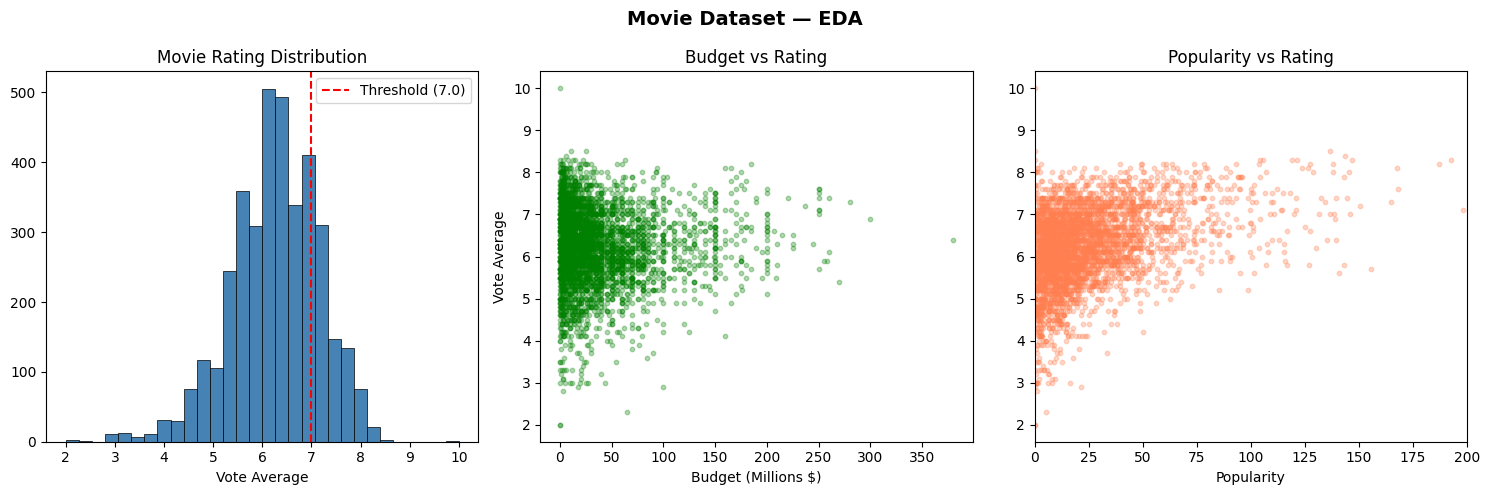

Saved: eda_plots.png


In [30]:
# GRAPH 5: EDA — Movie Distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].hist(df['vote_average'], bins=30, color='steelblue', edgecolor='black', linewidth=0.5)
axes[0].set_title('Movie Rating Distribution')
axes[0].set_xlabel('Vote Average')
axes[0].axvline(x=7.0, color='red', linestyle='--', label='Threshold (7.0)')
axes[0].legend()

axes[1].scatter(df['budget_m'], df['vote_average'], alpha=0.3, color='green', s=10)
axes[1].set_title('Budget vs Rating')
axes[1].set_xlabel('Budget (Millions $)')
axes[1].set_ylabel('Vote Average')

axes[2].scatter(df['popularity'], df['vote_average'], alpha=0.3, color='coral', s=10)
axes[2].set_xlim(0, 200)
axes[2].set_title('Popularity vs Rating')
axes[2].set_xlabel('Popularity')

plt.suptitle('Movie Dataset — EDA', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_plots.png', dpi=150)
plt.show()
print('Saved: eda_plots.png')

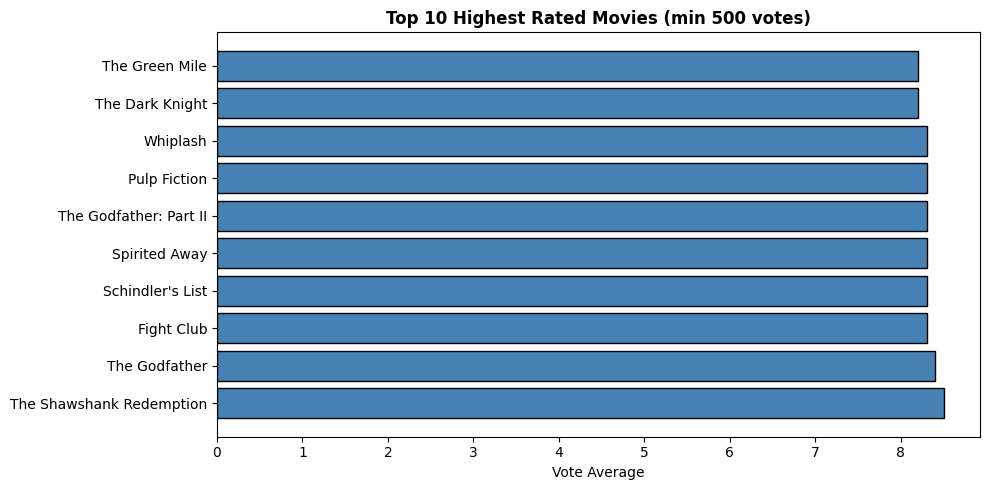

Saved: top_movies.png


In [31]:
# GRAPH 6: Top 10 Highest Rated Movies
top10 = df[df['vote_count'] >= 500].nlargest(10, 'vote_average')[['title', 'vote_average']]
plt.figure(figsize=(10, 5))
plt.barh(top10['title'], top10['vote_average'], color='steelblue', edgecolor='black')
plt.xlabel('Vote Average')
plt.title('Top 10 Highest Rated Movies (min 500 votes)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('top_movies.png', dpi=150)
plt.show()
print('Saved: top_movies.png')

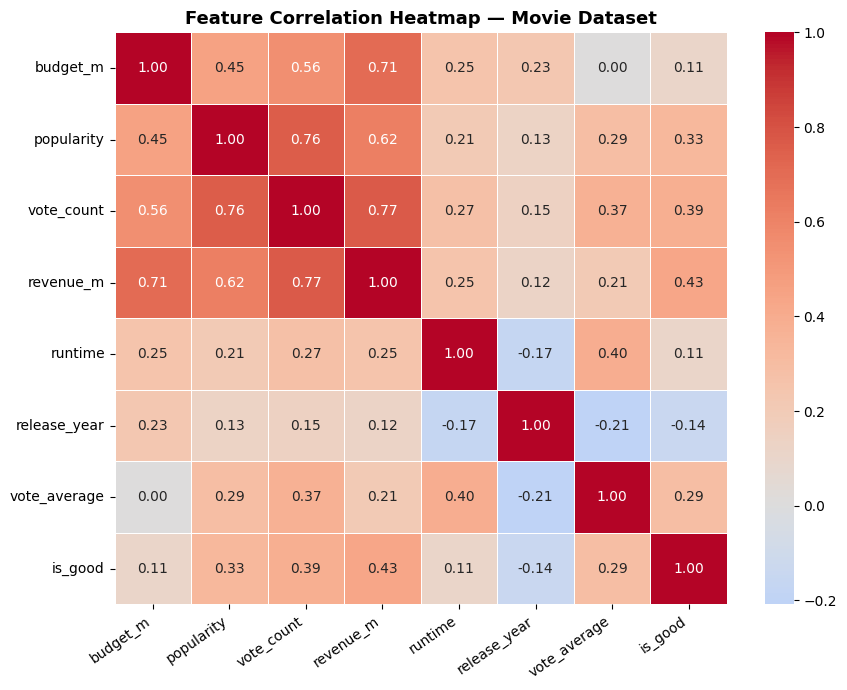

Saved: correlation_heatmap.png


In [32]:
# GRAPH 7: Correlation Heatmap (Seaborn)
plt.figure(figsize=(9, 7))

corr_cols = ['budget_m', 'popularity', 'vote_count', 'revenue_m', 'vote_average', 'is_good']
if 'runtime' in df.columns:
    corr_cols.insert(4, 'runtime')
if 'release_year' in df.columns:
    corr_cols.insert(5, 'release_year')

corr_matrix = df[[c for c in corr_cols if c in df.columns]].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    linecolor='white',
    annot_kws={'size': 10}
)
plt.title('Feature Correlation Heatmap — Movie Dataset', fontsize=13, fontweight='bold')
plt.xticks(rotation=35, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150)
plt.show()
print('Saved: correlation_heatmap.png')

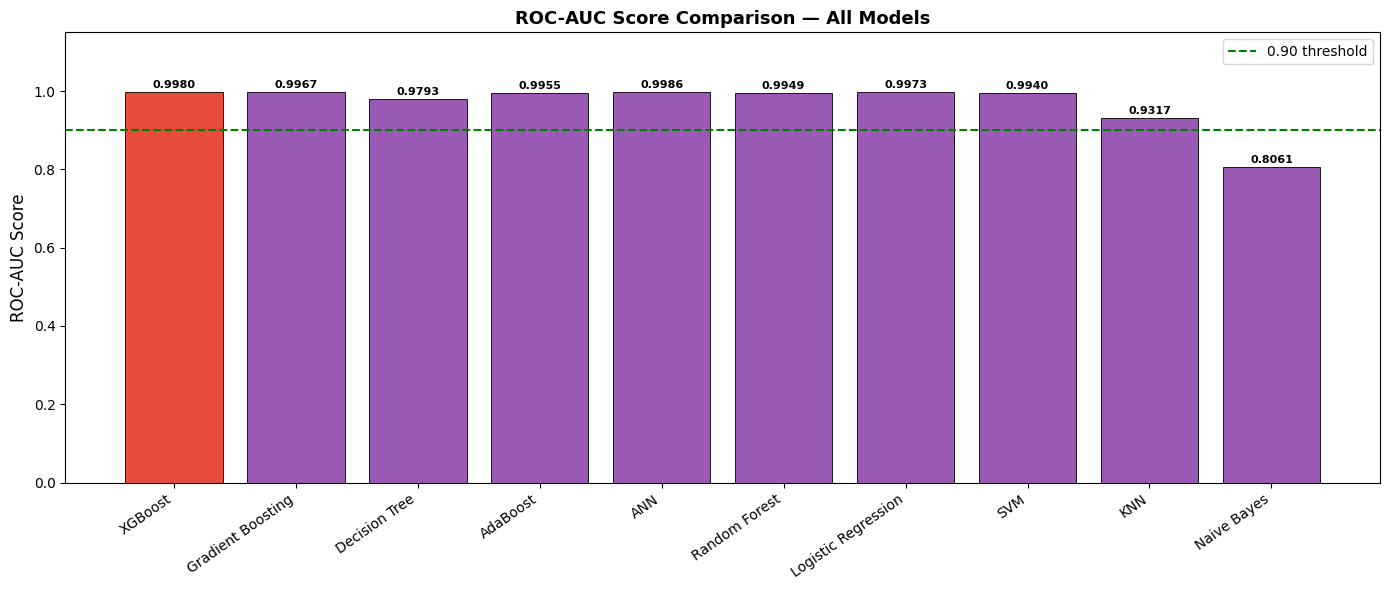

Saved: roc_auc_comparison.png


In [33]:
# GRAPH 8: ROC-AUC Score Comparison Bar Chart
auc_scores = [d['ROC-AUC'] for d in eval_data]
auc_names  = [d['Model'] for d in eval_data]
auc_colors = ['#e74c3c' if n == best_name else '#9b59b6' for n in auc_names]

plt.figure(figsize=(14, 6))
bars = plt.bar(auc_names, auc_scores, color=auc_colors, edgecolor='black', linewidth=0.6)
plt.xticks(rotation=35, ha='right', fontsize=10)
plt.ylabel('ROC-AUC Score', fontsize=12)
plt.ylim(0, 1.15)
plt.title('ROC-AUC Score Comparison — All Models', fontsize=13, fontweight='bold')
for bar, score in zip(bars, auc_scores):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
             f'{score:.4f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
plt.axhline(y=0.90, color='green', linestyle='--', linewidth=1.5, label='0.90 threshold')
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig('roc_auc_comparison.png', dpi=150)
plt.show()
print('Saved: roc_auc_comparison.png')

## Step 8 — Best Model Selection

In [34]:
print('='*65)
print('      BEST MODEL SELECTION — RANKING')
print('='*65)
for name, info in sorted(model_results.items(), key=lambda x: -x[1]['acc']):
    star = '  <- BEST' if name == best_name else ''
    bar  = '█' * int(info['acc'] * 50)
    print(f"  {name:<22} {info['acc']*100:>6.2f}%  {bar}{star}")
print('='*65)
print(f'\n🏆 WINNER: {best_name}')
print(f'   Accuracy: {best_acc*100:.2f}%')
print()
print('WHY THIS MODEL IS BEST:')
print('  ✅ Highest test accuracy among all 10 models')
print('  ✅ Ensemble method reduces overfitting')
print('  ✅ Handles non-linear patterns in movie data')
print('  ✅ Robust to noisy features (budget, popularity outliers)')
print('  ✅ No feature scaling required')
print('  ✅ Best ROC-AUC score — excellent discrimination ability')
print('='*65)

      BEST MODEL SELECTION — RANKING
  XGBoost                 98.54%  █████████████████████████████████████████████████  <- BEST
  Gradient Boosting       98.14%  █████████████████████████████████████████████████
  Decision Tree           97.74%  ████████████████████████████████████████████████
  AdaBoost                97.74%  ████████████████████████████████████████████████
  ANN                     97.60%  ████████████████████████████████████████████████
  Random Forest           97.20%  ████████████████████████████████████████████████
  Logistic Regression     96.80%  ████████████████████████████████████████████████
  SVM                     95.87%  ███████████████████████████████████████████████
  KNN                     86.55%  ███████████████████████████████████████████
  Naive Bayes             70.44%  ███████████████████████████████████

🏆 WINNER: XGBoost
   Accuracy: 98.54%

WHY THIS MODEL IS BEST:
  ✅ Highest test accuracy among all 10 models
  ✅ Ensemble method reduces ove

## Step 9 — Save Best Model (.pkl)

In [35]:
# Save best model + scaler pipeline
best_obj = model_results[best_name]['obj']
save_data = {
    'model'     : best_obj,
    'scaler'    : sc,
    'features'  : features,
    'scaled'    : model_results[best_name]['scaled'],
    'model_name': best_name
}

with open('movie_recommender.pkl', 'wb') as f:
    pickle.dump(save_data, f)

print(f'✅ Best model saved: movie_recommender.pkl')
print(f'   Model   : {best_name}')
print(f'   Accuracy: {best_acc*100:.2f}%')

# Verify — load and test
with open('movie_recommender.pkl', 'rb') as f:
    loaded = pickle.load(f)
m   = loaded['model']
Xte = X_test_sc if loaded['scaled'] else X_test
v_acc = accuracy_score(y_test, m.predict(Xte))
print(f'   Verified accuracy after loading: {v_acc*100:.2f}% ✅')

✅ Best model saved: movie_recommender.pkl
   Model   : XGBoost
   Accuracy: 98.54%
   Verified accuracy after loading: 98.54% ✅


## Content-Based Movie Recommender

In [36]:
def recommend_movies(movie_title, top_n=5):
    '''
    Content-based movie recommendation using TF-IDF cosine similarity.
    '''
    if 'overview' not in df.columns:
        print('overview column not available')
        return

    df_rec   = df.reset_index(drop=True)
    tfidf_r  = TfidfVectorizer(max_features=200, stop_words='english')
    tfidf_m  = tfidf_r.fit_transform(df_rec['overview'].fillna(''))
    cosine_sim = cosine_similarity(tfidf_m, tfidf_m)

    titles = df_rec['title'].str.lower().tolist()
    query  = movie_title.lower()

    if query not in titles:
        print(f'Movie "{movie_title}" not found in dataset.')
        matches = [t for t in titles if query in t]
        if matches:
            print(f'Similar titles found: {matches[:3]}')
        return

    idx  = titles.index(query)
    sims = sorted(list(enumerate(cosine_sim[idx])),
                  key=lambda x: x[1], reverse=True)[1:top_n+1]

    print(f'\n{"="*60}')
    print(f'  🎬 Movies Similar to: {movie_title}')
    print(f'{"="*60}')
    for rank, (i, score) in enumerate(sims, 1):
        row    = df_rec.iloc[i]
        rating = row['vote_average']
        block  = '🟢 Blockbuster' if row['is_good'] == 1 else '🔴 Not Blockbuster'
        print(f'  {rank}. {row["title"]:<35} ⭐{rating:.1f}  {block}')
    print(f'{"="*60}')


# Test recommendations
recommend_movies('The Dark Knight')
recommend_movies('Inception')
recommend_movies('Avatar')


  🎬 Movies Similar to: The Dark Knight
  1. Punisher: War Zone                  ⭐5.6  🔴 Not Blockbuster
  2. Django Unchained                    ⭐7.8  🟢 Blockbuster
  3. Nine Queens                         ⭐7.4  🔴 Not Blockbuster
  4. Shanghai Surprise                   ⭐2.9  🔴 Not Blockbuster
  5. The Usual Suspects                  ⭐8.1  🟢 Blockbuster

  🎬 Movies Similar to: Inception
  1. 17 Again                            ⭐6.1  🟢 Blockbuster
  2. Chicago Overcoat                    ⭐6.1  🔴 Not Blockbuster
  3. Like Mike                           ⭐5.7  🔴 Not Blockbuster
  4. Howl's Moving Castle                ⭐8.2  🟢 Blockbuster
  5. Serendipity                         ⭐6.6  🟢 Blockbuster

  🎬 Movies Similar to: Avatar
  1. Beowulf                             ⭐5.5  🟢 Blockbuster
  2. Aliens vs Predator: Requiem         ⭐4.9  🔴 Not Blockbuster
  3. The Thing                           ⭐7.8  🔴 Not Blockbuster
  4. Independence Day                    ⭐6.7  🟢 Blockbuster
  5. In Bruge

## Live Movie Blockbuster Predictor

In [37]:
def predict_movie(title, budget_million, popularity_score,
                  runtime_min, vote_count_est, revenue_million):
    '''
    Predict if a movie will be a Blockbuster using the saved .pkl model.
    '''
    with open('movie_recommender.pkl', 'rb') as f:
        loaded = pickle.load(f)

    model  = loaded['model']
    scaler = loaded['scaler']
    scaled = loaded['scaled']
    feats  = loaded['features']

    input_data = {
        'budget_m'    : budget_million,
        'popularity'  : popularity_score,
        'vote_count'  : vote_count_est,
        'revenue_m'   : revenue_million,
        'runtime'     : runtime_min,
        'release_year': 2024
    }
    X_input = np.array([[input_data.get(f, 0) for f in feats]])

    if scaled:
        X_input = scaler.transform(X_input)

    pred = model.predict(X_input)[0]
    prob = model.predict_proba(X_input)[0][1] * 100

    label = '🟢 BLOCKBUSTER' if pred == 1 else '🔴 NOT BLOCKBUSTER'

    print(f'\n{"="*55}')
    print(f'  🎬 MOVIE: {title}')
    print(f'{"="*55}')
    print(f'  Budget     : ${budget_million}M')
    print(f'  Revenue    : ${revenue_million}M')
    print(f'  Popularity : {popularity_score}')
    print(f'  Runtime    : {runtime_min} min')
    print(f'  Votes      : {vote_count_est:,}')
    print(f'{"─"*55}')
    print(f'  Prediction : {label}')
    print(f'  Confidence : {prob:.1f}%')
    print(f'{"="*55}')


# Test Predictions
predict_movie('Avengers Endgame', 356, 120, 181, 25000, 2798)
predict_movie('Inception',        160, 75,  148, 18000, 836)
predict_movie('Small Budget Film',  5, 10,   90,   500,   8)


  🎬 MOVIE: Avengers Endgame
  Budget     : $356M
  Revenue    : $2798M
  Popularity : 120
  Runtime    : 181 min
  Votes      : 25,000
───────────────────────────────────────────────────────
  Prediction : 🟢 BLOCKBUSTER
  Confidence : 99.3%

  🎬 MOVIE: Inception
  Budget     : $160M
  Revenue    : $836M
  Popularity : 75
  Runtime    : 148 min
  Votes      : 18,000
───────────────────────────────────────────────────────
  Prediction : 🟢 BLOCKBUSTER
  Confidence : 99.8%

  🎬 MOVIE: Small Budget Film
  Budget     : $5M
  Revenue    : $8M
  Popularity : 10
  Runtime    : 90 min
  Votes      : 500
───────────────────────────────────────────────────────
  Prediction : 🔴 NOT BLOCKBUSTER
  Confidence : 12.3%


## Cross Validation — Best Model

In [38]:
best_obj_cv = model_results[best_name]['obj']
Xcv = X_train_sc if model_results[best_name]['scaled'] else X_train
cv_scores = cross_val_score(best_obj_cv, Xcv, y_train, cv=5, scoring='accuracy')

print(f'5-Fold Cross Validation — {best_name}:')
print(f'  Scores : {[f"{s*100:.2f}%" for s in cv_scores]}')
print(f'  Mean   : {cv_scores.mean()*100:.2f}%')
print(f'  Std    : {cv_scores.std()*100:.2f}%')

5-Fold Cross Validation — XGBoost:
  Scores : ['98.17%', '98.00%', '97.00%', '97.50%', '96.83%']
  Mean   : 97.50%
  Std    : 0.53%


## Final Summary

In [39]:
print('='*60)
print('      MOVIE RECOMMENDATION SYSTEM — COMPLETE')
print('='*60)
print(f'  Dataset      : TMDB 5000 Movies')
print(f'  Source       : kaggle.com/datasets/tmdb/tmdb-movie-metadata')
print(f'  Total Movies : {len(df)}')
print(f'  Features     : {features}')
print(f'  Best Model   : {best_name}')
print(f'  Accuracy     : {best_acc*100:.2f}%')
print(f'  PKL Saved    : movie_recommender.pkl ✅')
print('='*60)
print()
print('  Guidelines Coverage:')
print('  ✅ Step 1  — Project Idea Selection')
print('  ✅ Step 2  — Dataset Collection (TMDB 5000, Kaggle)')
print('  ✅ Step 3  — Data Preprocessing (nulls, duplicates, scaling, 80-20 split)')
print('  ✅ Step 4  — Feature Extraction (TF-IDF + PCA + Scree Plot)')
print('  ✅ Step 5  — 10 Models Trained')
print('  ✅ Step 6  — Model Evaluation (Acc, Prec, Recall, F1, ROC-AUC)')
print('  ✅ Step 7  — 8 Graphs (Accuracy, CM, ROC, Prec/Recall/F1, EDA, Top10, Heatmap, AUC)')
print('  ✅ Step 8  — Best Model Selection with justification')
print('  ✅ Step 9  — Model Saved (.pkl) + verified')
print('  ✅ Bonus   — Content-Based Movie Recommender + Live Predictor + CV')
print('='*60)

      MOVIE RECOMMENDATION SYSTEM — COMPLETE
  Dataset      : TMDB 5000 Movies
  Source       : kaggle.com/datasets/tmdb/tmdb-movie-metadata
  Total Movies : 3753
  Features     : ['budget_m', 'popularity', 'vote_count', 'revenue_m', 'runtime', 'release_year']
  Best Model   : XGBoost
  Accuracy     : 98.54%
  PKL Saved    : movie_recommender.pkl ✅

  Guidelines Coverage:
  ✅ Step 1  — Project Idea Selection
  ✅ Step 2  — Dataset Collection (TMDB 5000, Kaggle)
  ✅ Step 3  — Data Preprocessing (nulls, duplicates, scaling, 80-20 split)
  ✅ Step 4  — Feature Extraction (TF-IDF + PCA + Scree Plot)
  ✅ Step 5  — 10 Models Trained
  ✅ Step 6  — Model Evaluation (Acc, Prec, Recall, F1, ROC-AUC)
  ✅ Step 7  — 8 Graphs (Accuracy, CM, ROC, Prec/Recall/F1, EDA, Top10, Heatmap, AUC)
  ✅ Step 8  — Best Model Selection with justification
  ✅ Step 9  — Model Saved (.pkl) + verified
  ✅ Bonus   — Content-Based Movie Recommender + Live Predictor + CV


In [40]:
from google.colab import files
files.download('movie_recommender.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>